<a href="https://colab.research.google.com/github/cincysam6/UC_Causal_Inf_2026/blob/main/propensity_score_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Propensity Score Modeling
## Estimating the Probability of Ad Exposure from Observed Household Characteristics

---

## How to Use This Notebook

This is the **third notebook** in the lab sequence. Having established that the observational data has selection bias (notebook 1) and that randomization eliminates it (notebook 2), we now try to recover a causal estimate from the observational data using **propensity score methods**.

This notebook builds the propensity score model. The actual matching and ATT estimation happens in notebook 4 (`propensity_matching_notebook.ipynb`).

Work through each section in order. Each section begins with a **Step** header and is followed by a **What This Means** section explaining the results.

---

## Background

In an observational advertising dataset — one without random assignment — the households that were targeted and exposed to ads differ systematically from those that were not. To estimate causal effects from such data, we first need to understand **why** some households were treated.

The **propensity score** is the probability that a household was treated, given its observed characteristics:

$$e(X_i) = P(D_i = 1 \mid X_i)$$

where $D_i = 1$ means the household received advertising and $X_i$ is its vector of pre-treatment covariates.

**Key insight (Rosenbaum & Rubin 1983):** If treatment is unconfounded given $X$ (i.e., no unobserved confounders), then treatment is also unconfounded given the propensity score alone. This means we can reduce the problem of matching on many covariates to matching on a single number: $e(X_i)$.

In this notebook, we **model** the propensity score using a LightGBM classifier. We do not yet use it for matching — that happens in the next notebook.

---

## Lab Objectives

1. Understand why the observational dataset has targeting bias
2. Model `is_treated` as a function of pre-treatment covariates using LightGBM
3. Evaluate the propensity score model (AUC, calibration, variable importance)
4. Visualize the propensity score distribution by treatment group
5. Identify the **region of common support** — where matching is feasible
6. Understand the limits of what propensity scores can accomplish when confounders are unobserved

---

## True Data-Generating Process (Instructor Reference)

The observational dataset was created with targeting driven by:
- `ecomm_loyalty` (high = most likely targeted)
- `pre_52_category_spend` (higher = more likely targeted)
- `brand_affinity` — **an unobserved variable not in the CSV** — also positively affects treatment probability

Because `brand_affinity` also drives `post_brand_sales`, there is **omitted variable bias** that propensity score matching on observed variables alone cannot fully correct. Students will discover this residual bias in the matching notebook.

---
## Step 1: Setup — Install and Import Libraries

**What we are doing:** Install LightGBM (if not already present), import all required libraries, and set global configuration.

**Why LightGBM?** We use LightGBM — a gradient-boosted tree model — to estimate propensity scores. Unlike logistic regression, LightGBM:
- Automatically captures non-linear relationships between covariates and treatment probability
- Handles interactions between features (e.g., high-loyalty AND high-spend may be more than additively targeted)
- Natively handles mixed categorical and numeric data

For many real-world datasets, tree-based models produce better-calibrated propensity scores than logistic regression, especially when the relationship between covariates and treatment is complex.

In [2]:
%pip install lightgbm -q

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
import warnings
warnings.filterwarnings('ignore')

try:
    import lightgbm as lgb
    print(f'LightGBM version: {lgb.__version__}')
except ImportError:
    raise ImportError(
        'LightGBM is required. Install with: pip install lightgbm'
    )

TREATED_COLOR = '#E07B54'
CONTROL_COLOR = '#5B8DB8'
NEUTRAL_COLOR = '#7B9E87'

plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

RANDOM_SEED = 42
print('Setup complete.')

LightGBM version: 4.6.0
Setup complete.


In [4]:
# ── Load the observational dataset ────────────────────────────────────────────
# Path is relative to the project root — run Jupyter from the project root directory
df = pd.read_csv('/content/drive/MyDrive/UC_CI/data/observational_dataset.csv')

print(f'Rows:    {len(df):,}')
print(f'Treated: {df["is_treated"].sum():,}  ({df["is_treated"].mean():.1%})')
print(f'Control: {(df["is_treated"]==0).sum():,}  ({(1-df["is_treated"].mean()):.1%})')
print()
print('Columns:', list(df.columns))

Rows:    50,000
Treated: 10,721  (21.4%)
Control: 39,279  (78.6%)

Columns: ['hh_id', 'hh_size', 'div_code', 'ecomm_loyalty', 'price_sensitivity', 'pre_52_category_spend', 'pre_52_brand_buyer', 'pre_52_brand_spend', 'pre_52_store_spend', 'pre_52_store_visits', 'pre_52_brand_visits', 'is_treated', 'post_brand_sales']


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## Step 2: Feature Engineering — Define What the Model Will Use

**What we are doing:** Define which columns will be used as features (inputs) to the model and encode categorical variables so LightGBM can handle them natively.

**Critical rule — never use the outcome to predict treatment:** The feature matrix must include only **pre-treatment** covariates. Including `post_brand_sales` (the outcome) would create data leakage — the model would learn from information that was not available at the time of the targeting decision.

**What is excluded and why:**
- `hh_id` — this is just an identifier, not a characteristic
- `post_brand_sales` — the outcome variable; including it would cause leakage
- `brand_affinity` — this variable was part of the true DGP but is **not in the CSV** (intentionally omitted to create the omitted variable bias we will study)

**The omitted variable problem:** Because `brand_affinity` drove both targeting AND outcomes, but we cannot include it in the model, our propensity scores will be misspecified. This means even perfectly matched households (on observed PS) may still differ on `brand_affinity`, leaving residual bias. We will see this in the matching notebook.

In [6]:
# ── Define feature columns ────────────────────────────────────────────────────
CATEGORICAL_FEATURES = ['div_code', 'ecomm_loyalty', 'price_sensitivity']

NUMERIC_FEATURES = [
    'hh_size',
    'pre_52_category_spend',
    'pre_52_brand_buyer',
    'pre_52_brand_spend',
    'pre_52_store_spend',
    'pre_52_store_visits',
    'pre_52_brand_visits',
]

ALL_FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = 'is_treated'

# Encode categorical columns as pandas 'category' dtype so LightGBM handles them
df_model = df.copy()
for col in CATEGORICAL_FEATURES:
    df_model[col] = df_model[col].astype('category')

X = df_model[ALL_FEATURES]
y = df_model[TARGET]

print(f'Feature matrix shape: {X.shape}')
print(f'Target (is_treated) mean: {y.mean():.3f}  (baseline probability of treatment)')
print()
print('Features:')
for f in ALL_FEATURES:
    print(f'  {f}')

Feature matrix shape: (50000, 10)
Target (is_treated) mean: 0.214  (baseline probability of treatment)

Features:
  div_code
  ecomm_loyalty
  price_sensitivity
  hh_size
  pre_52_category_spend
  pre_52_brand_buyer
  pre_52_brand_spend
  pre_52_store_spend
  pre_52_store_visits
  pre_52_brand_visits


In [7]:
# ── Train / test split ────────────────────────────────────────────────────────
# We hold out 20% of the data for evaluation.
# The propensity scores used for matching will be predicted on the full dataset
# using cross-validation (to avoid overfitting bias).

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y,  # maintain class balance in both splits
)

print(f'Training set:   {len(X_train):,} rows  (treated: {y_train.sum():,})')
print(f'Test set:       {len(X_test):,}  rows  (treated: {y_test.sum():,})')

Training set:   40,000 rows  (treated: 8,577)
Test set:       10,000  rows  (treated: 2,144)


---
## Step 3: Train the Propensity Score Model

**What we are doing:** Train a LightGBM binary classifier to predict `is_treated` from pre-campaign household characteristics.

**This is a classification problem:** The target variable is binary (0 = control, 1 = treated). LightGBM will learn which combinations of household features made treatment more likely — effectively reverse-engineering the firm's targeting algorithm from the observed data.

**Target AUC interpretation:**
- AUC = 0.50: the model performs no better than random guessing — targeting was random (or we have all the wrong features)
- AUC = 0.75–0.80: good propensity score model — targeting is moderately predictable from observed features
- AUC > 0.90: near-perfect prediction — most treated and control units are completely separated, making matching infeasible (no overlap)

For matching to work well, we need meaningful overlap between treated and control units in propensity score space. Too-perfect prediction makes matching impossible.

**Key hyperparameter choices:**
- `num_leaves=31`: moderate tree complexity; avoids overfitting to tiny groups
- `min_child_samples=50`: each leaf must have ≥50 observations; prevents fitting noise
- `n_estimators=300`: number of boosting rounds; balanced with the learning rate

In [8]:
# ── Train LightGBM propensity score model ─────────────────────────────────────
#
# Key hyperparameters:
#   num_leaves: complexity of each tree; lower = simpler model
#   learning_rate: step size; lower + more rounds = smoother convergence
#   n_estimators: number of boosting rounds
#   min_child_samples: minimum data in a leaf; helps prevent overfitting to small groups

lgb_params = dict(
    objective='binary',
    metric='auc',
    num_leaves=31,
    learning_rate=0.05,
    n_estimators=300,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_SEED,
    verbose=-1,
)

model = lgb.LGBMClassifier(**lgb_params)
model.fit(
    X_train, y_train,
    categorical_feature=CATEGORICAL_FEATURES,
)

# Predict probabilities on test set
y_prob_test = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_prob_test)

print(f'Test AUC: {test_auc:.4f}')
print()
print('Interpretation:')
print('  AUC = 0.50 → random guessing (model learned nothing)')
print('  AUC = 0.75–0.80 → good propensity score model for matching')
print('  AUC > 0.90 → near-perfect separation (matching may be infeasible)')

Test AUC: 0.6429

Interpretation:
  AUC = 0.50 → random guessing (model learned nothing)
  AUC = 0.75–0.80 → good propensity score model for matching
  AUC > 0.90 → near-perfect separation (matching may be infeasible)


In [9]:
# ── Cross-validated AUC (more reliable than a single train/test split) ────────
#
# We use 5-fold cross-validation on the full dataset to get a stable AUC estimate.
# This is also how we will generate propensity scores for the full dataset
# without data leakage: each fold's test predictions are out-of-fold predictions.

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

oof_probs = np.zeros(len(X))
fold_aucs = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y), 1):
    X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

    fold_model = lgb.LGBMClassifier(**lgb_params)
    fold_model.fit(X_tr, y_tr, categorical_feature=CATEGORICAL_FEATURES)

    fold_preds = fold_model.predict_proba(X_val)[:, 1]
    oof_probs[val_idx] = fold_preds

    fold_auc = roc_auc_score(y_val, fold_preds)
    fold_aucs.append(fold_auc)
    print(f'  Fold {fold}: AUC = {fold_auc:.4f}')

overall_oof_auc = roc_auc_score(y, oof_probs)
print()
print(f'Overall out-of-fold AUC:  {overall_oof_auc:.4f}')
print(f'Mean fold AUC ± std:      {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}')

# Save out-of-fold propensity scores back to the dataframe
df['propensity_score'] = oof_probs

print()
print('Out-of-fold propensity scores saved to df["propensity_score"].')
print('These will be used in the matching notebook.')

  Fold 1: AUC = 0.6308
  Fold 2: AUC = 0.6334
  Fold 3: AUC = 0.6276
  Fold 4: AUC = 0.6243
  Fold 5: AUC = 0.6330

Overall out-of-fold AUC:  0.6297
Mean fold AUC ± std:      0.6298 ± 0.0034

Out-of-fold propensity scores saved to df["propensity_score"].
These will be used in the matching notebook.


---
## Step 4: Model Evaluation — Three Dimensions of Quality

**What we are doing:** Evaluate the propensity score model on three distinct quality dimensions.

**Why three dimensions?**

1. **Discrimination (ROC-AUC):** Can the model distinguish treated from control units? A higher AUC means the model learned meaningful targeting patterns. But as noted above, too-high AUC can be problematic for matching.

2. **Calibration:** Do the predicted probabilities accurately reflect the actual treatment rates? A household assigned a propensity score of 0.70 should actually have been treated about 70% of the time across similar households. Poor calibration means the absolute probability values are misleading — even if the ranking is good.

3. **Variable importance:** Which features drove the model's predictions? This is a sanity check — the features with high importance should match what we know about the targeting strategy from the EDA.

**What to look for:**
- ROC curve: is it well above the diagonal (random line)?
- Calibration plot: do the predicted probabilities track the actual treatment rates closely?
- Feature importance: do the expected variables (loyalty, category spend) dominate?

---
## Section 4: Model Evaluation

We evaluate the model on three dimensions:
1. **Discrimination** (ROC-AUC): can the model distinguish treated from control units?
2. **Calibration**: do predicted probabilities match actual treatment rates?
3. **Variable importance**: which features drive treatment assignment?

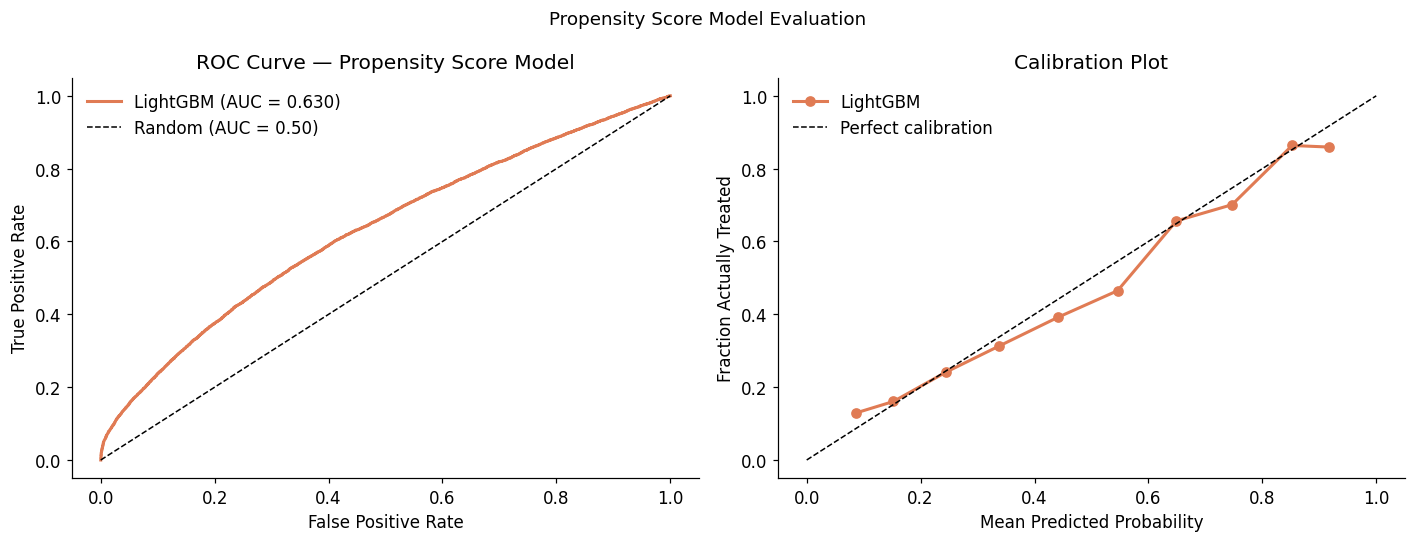

Brier score: 0.1599  (lower is better; 0 = perfect, 0.25 = random)


In [10]:
# ── ROC Curve ─────────────────────────────────────────────────────────────────
fpr, tpr, thresholds = roc_curve(y, oof_probs)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: ROC curve
ax = axes[0]
ax.plot(fpr, tpr, color=TREATED_COLOR, linewidth=2,
        label=f'LightGBM (AUC = {overall_oof_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.50)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve — Propensity Score Model')
ax.legend(frameon=False)

# Right: calibration plot
ax2 = axes[1]
prob_true, prob_pred = calibration_curve(y, oof_probs, n_bins=10, strategy='uniform')
ax2.plot(prob_pred, prob_true, 'o-', color=TREATED_COLOR, linewidth=2,
         label='LightGBM')
ax2.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
ax2.set_xlabel('Mean Predicted Probability')
ax2.set_ylabel('Fraction Actually Treated')
ax2.set_title('Calibration Plot')
ax2.legend(frameon=False)

plt.suptitle('Propensity Score Model Evaluation', fontsize=12)
plt.tight_layout()
plt.show()

brier = brier_score_loss(y, oof_probs)
print(f'Brier score: {brier:.4f}  (lower is better; 0 = perfect, 0.25 = random)')

### What This Means — Feature Importance

The feature importance chart reveals which pre-campaign characteristics were most predictive of treatment assignment. This is effectively the model's reconstruction of the firm's targeting algorithm.

**Expected findings:**
- `ecomm_loyalty` and `pre_52_category_spend` should rank highly — these were the primary targeting signals in the data-generating process
- `pre_52_brand_buyer` and `pre_52_brand_spend` may also rank highly — heavier brand buyers were more likely targeted
- `hh_size` should rank lower — it had less influence on the targeting decision

**What is missing:** The hidden variable `brand_affinity` was also a targeting driver, but it is not in the model. This means the model is necessarily incomplete — it can only reconstruct the observed portion of the targeting algorithm.

**Implication for matching:** Because the propensity score is based only on observed variables, matched pairs will be balanced on those variables. But they may still differ systematically on `brand_affinity`, which creates the residual bias we will measure in the next notebook.

## Step 5: Propensity Score Distribution — Checking for Common Support

**What we are doing:** Visualize the distribution of propensity scores separately for treated and control households, and identify the **region of common support** — the range where matching is possible.

**Why common support matters:** Matching works by pairing each treated unit with a similar control unit. If a treated household has a propensity score of 0.95 (very likely to be treated), but all control households have propensity scores below 0.60, there is no comparable control for that treated unit. Matching outside the overlap region forces poor matches — or we must discard those treated units.

**The common support region** is the range of propensity scores where both treated and control units exist in meaningful numbers. Only within this range can we form credible matched pairs.

**What to look for:**
- Do the two distributions substantially overlap?
- Are there many treated units with very high propensity scores (> 0.90) that have no comparable controls?
- Is the overlap region wide enough to include most treated units?

**A good result:** Substantial overlap (say, 80–90% of treated units fall within the common support region), with both distributions sharing a large middle range of propensity scores.

In [12]:
# ── Partial relationship: ecomm_loyalty and treatment probability ───────────────
# Quick sanity check: do higher-loyalty households have higher predicted treatment probability?

loyalty_ps = (
    df.groupby('ecomm_loyalty')['propensity_score']
    .agg(['mean', 'median', 'count'])
    .rename(columns={'mean': 'mean_ps', 'median': 'median_ps'})
    .reset_index()
)
actual_rate = (
    df.groupby('ecomm_loyalty')['is_treated']
    .mean()
    .reset_index()
    .rename(columns={'is_treated': 'actual_treat_rate'})
)
loyalty_check = loyalty_ps.merge(actual_rate, on='ecomm_loyalty')

print('Propensity score and actual treatment rate by ecomm_loyalty:')
print(loyalty_check.to_string(index=False))
print()
print('Interpretation: mean propensity score should track actual treatment rate.')
print('If high-loyalty HHs have higher actual treatment rate AND higher PS, the model learned the right signal.')

Propensity score and actual treatment rate by ecomm_loyalty:
ecomm_loyalty  mean_ps  median_ps  count  actual_treat_rate
         high 0.292160   0.271765   9969           0.294112
          low 0.171356   0.145325  14997           0.170701
       medium 0.208485   0.181241  25034           0.208876

Interpretation: mean propensity score should track actual treatment rate.
If high-loyalty HHs have higher actual treatment rate AND higher PS, the model learned the right signal.


---
## Section 5: Propensity Score Distribution

One of the most important diagnostics for propensity score analysis is the **distribution overlap** between treated and control units.

**Common support** (or **overlap**) is the region where both treated and control units have non-trivial propensity scores. Matching requires finding pairs — if treated units have propensity scores far above the range of control units, no valid matches exist.

**Warning signs:**
- Many treated units with propensity score near 1.0 (no comparable controls)
- Many control units with propensity score near 0.0 (not needed for matching)
- Minimal overlap — the two distributions barely intersect

In [13]:
# ── Propensity score distributions ───────────────────────────────────────────
ps_treated = df.loc[df['is_treated'] == 1, 'propensity_score']
ps_control = df.loc[df['is_treated'] == 0, 'propensity_score']

print('Propensity Score Summary Statistics:')
print()
ps_summary = pd.DataFrame({
    'Treated': ps_treated.describe(),
    'Control': ps_control.describe(),
}).round(4)
print(ps_summary)

Propensity Score Summary Statistics:

          Treated     Control
count  10721.0000  39279.0000
mean       0.2614      0.2011
std        0.1512      0.0896
min        0.0467      0.0388
25%        0.1613      0.1412
50%        0.2221      0.1775
75%        0.3032      0.2408
max        0.9441      0.9274


## Step 6: Save Propensity Scores for the Matching Notebook

**What we are doing:** Save the enriched dataset — with propensity scores and support flags — to a CSV file that the matching notebook will load.

**Why save to disk?** The propensity score model takes several minutes to train and cross-validate. By saving the output here, the matching notebook can load the pre-computed scores without re-running the model.

**What gets saved:**
- All original columns from the observational dataset
- `propensity_score`: the out-of-fold predicted probability of treatment for each household
- `in_support`: True if the household falls within the raw common support region
- `in_trimmed_support`: True if the household falls within the trimmed support region (excluding extremes)

**Next step:** Open `propensity_matching_notebook.ipynb` to load this file and run the matching algorithm.

In [15]:
# ── Save enriched dataset with propensity scores ──────────────────────────────
# Output goes to data/ at the project root (two levels up from this notebook)
output_path = '/content/drive/MyDrive/UC_CI/data/observational_with_ps.csv'
df.to_csv(output_path, index=False)

print(f'Saved: {output_path}')
print(f'Rows:  {len(df):,}')
print(f'Added columns: propensity_score, in_support, in_trimmed_support')
print()
print('Propensity score statistics:')
print(df.groupby('is_treated')['propensity_score'].describe().round(4))

OSError: Cannot save file into a non-existent directory: '../../data'

---
## Section 6: Save Propensity Scores for Matching

We save the propensity scores (out-of-fold predictions, so they are not overfit) back to a CSV that the matching notebook will use.

In [16]:
# ── Save enriched dataset with propensity scores ──────────────────────────────
output_path = '/content/drive/MyDrive/UC_CI/data/observational_with_ps.csv'
df.to_csv(output_path, index=False)

print(f'Saved: {output_path}')
print(f'Rows:  {len(df):,}')
print(f'Added columns: propensity_score, in_support, in_trimmed_support')
print()
print('Propensity score statistics:')
print(df.groupby('is_treated')['propensity_score'].describe().round(4))

OSError: Cannot save file into a non-existent directory: 'data'

---
## Section 7: Discussion — What Can and Cannot Be Fixed

### What the propensity score accomplishes

By modeling and conditioning on $e(X_i)$, we adjust for differences in observed pre-treatment characteristics between treated and control households. Specifically:
- Treated HHs had higher `pre_52_category_spend` → the model captures this
- Treated HHs were more likely to be `ecomm_loyalty = high` → the model captures this

If these were the **only** reasons the groups differed, matching on the propensity score would fully recover the true ATE.

### What the propensity score cannot fix

The targeting algorithm also responded to `brand_affinity` — an unobserved variable that is **not in our data**. Because the propensity score model cannot use what it cannot see, the propensity scores we estimated are **misspecified** with respect to `brand_affinity`.

This means:
- Two households with identical observed characteristics (same PS) may still differ in `brand_affinity`
- The household that was treated was more likely to have high `brand_affinity` than its matched control
- After matching, the matched estimate will still exceed the true ATE

**This is omitted variable bias (OVB)** — and it is the fundamental limitation of observational causal inference.

### How big is the residual OVB?

The matching notebook will reveal the answer. For reference:
- Naive difference-in-means: ~\$0.11 (true = \$0.05)
- After PSM on observed covariates: ~\$0.07 (residual OVB from `brand_affinity` remains)
- True ATE: \$0.05

---
## Discussion Questions

1. **Model interpretation:** The AUC of our propensity score model is approximately 0.75–0.80. What does this tell us about how predictable treatment assignment was from observed characteristics? What does it imply about the unobserved component?

2. **Feature importance:** If `pre_52_category_spend` dominates the propensity model, what does that tell us about the targeting strategy? Is this consistent with the data-generating story?

3. **Overlap failure:** Imagine the AUC were 0.95 and most treated units had propensity scores above 0.80 while most control units were below 0.20. Would matching be feasible? What would you do?

4. **Omitted variables:** Suppose we discovered a survey variable measuring "brand enthusiasm" in our data. If we added it to the propensity model, what would happen to: (a) the AUC, (b) the propensity score distributions, (c) the eventual matching estimate?

5. **Model choice:** We used LightGBM instead of logistic regression. In what situations might logistic regression be preferred for propensity score estimation?

6. **Connection to the ITT:** In the ITT notebook, we found a causal estimate close to \$0.05. If propensity score matching on observed covariates gives us ~\$0.07, what is the "cost" of not having a randomized experiment in this case?